# 📱 Liquidity Stress Prediction Challenge - Starter Notebook

Welcome to the starter notebook for this challenge.

In this challenge, your goal is to build a machine learning model that predicts whether a customer is likely to experience liquidity stress, using historical mobile money behaviour.

This notebook walks through a simple end-to-end pipeline:

- Loading and exploring the data
- Preprocessing
- Training a baseline model
- Evaluating performance
- Generating predictions for submission

The baseline model used here is **Logistic Regression**, which is a good starting point for tabular classification problems.


In [147]:
# 📚 Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression


sns.set_style("whitegrid")
pd.set_option("display.max_columns", 200)


In [148]:
# 📥 Load the Data
train = pd.read_csv("Train.csv")
test = pd.read_csv("Test.csv")

SUBMISSION_TARGET = "Target"

# Create a sample submission template directly from the test IDs
sample_submission = pd.DataFrame({
    "ID": test["ID"],
    SUBMISSION_TARGET: 0.5
})

# Peek at the data
train.head()


,arpu,age,gender,region,smartphone,segment,earning_pattern,x_90_d_activity_rate,m1_paybill_volume,m1_paybill_total_value,m1_paybill_highest_amount,m1_paybill_companies,m2_paybill_volume,m2_paybill_total_value,m2_paybill_highest_amount,m2_paybill_companies,m3_paybill_volume,m3_paybill_total_value,m3_paybill_highest_amount,m3_paybill_companies,m4_paybill_volume,m4_paybill_total_value,m4_paybill_highest_amount,m4_paybill_companies,m5_paybill_volume,m5_paybill_total_value,m5_paybill_highest_amount,m5_paybill_companies,m6_paybill_volume,m6_paybill_total_value,m6_paybill_highest_amount,m6_paybill_companies,m1_merchantpay_volume,m1_merchantpay_total_value,m1_merchantpay_highest_amount,m1_merchantpay_merchants,m2_merchantpay_volume,m2_merchantpay_total_value,m2_merchantpay_highest_amount,m2_merchantpay_merchants,m3_merchantpay_volume,m3_merchantpay_total_value,m3_merchantpay_highest_amount,m3_merchantpay_merchants,m4_merchantpay_volume,m4_merchantpay_total_value,m4_merchantpay_highest_amount,m4_merchantpay_merchants,m5_merchantpay_volume,m5_merchantpay_total_value,m5_merchantpay_highest_amount,m5_merchantpay_merchants,m6_merchantpay_volume,m6_merchantpay_total_value,m6_merchantpay_highest_amount,m6_merchantpay_merchants,m1_transfer_from_bank_volume,m1_transfer_from_bank_total_value,m1_transfer_from_bank_highest_amount,m1_transfer_from_bank_banks,m2_transfer_from_bank_volume,m2_transfer_from_bank_total_value,m2_transfer_from_bank_highest_amount,m2_transfer_from_bank_banks,m3_transfer_from_bank_volume,m3_transfer_from_bank_total_value,m3_transfer_from_bank_highest_amount,m3_transfer_from_bank_banks,m4_transfer_from_bank_volume,m4_transfer_from_bank_total_value,m4_transfer_from_bank_highest_amount,m4_transfer_from_bank_banks,m5_transfer_from_bank_volume,m5_transfer_from_bank_total_value,m5_transfer_from_bank_highest_amount,m5_transfer_from_bank_banks,m6_transfer_from_bank_volume,m6_transfer_from_bank_total_value,m6_transfer_from_bank_highest_amount,m6_transfer_from_bank_banks,m1_mm_send_volume,m1_mm_send_total_value,m1_mm_send_highest_amount,m1_mm_send_recipients,m2_mm_send_volume,m2_mm_send_total_value,m2_mm_send_highest_amount,m2_mm_send_recipients,m3_mm_send_volume,m3_mm_send_total_value,m3_mm_send_highest_amount,m3_mm_send_recipients,m4_mm_send_volume,m4_mm_send_total_value,m4_mm_send_highest_amount,m4_mm_send_recipients,m5_mm_send_volume,m5_mm_send_total_value,m5_mm_send_highest_amount,m5_mm_send_recipients,m6_mm_send_volume,m6_mm_send_total_value,m6_mm_send_highest_amount,m6_mm_send_recipients,m1_received_volume,m1_received_total_value,m1_received_highest_amount,m1_received_senders,m2_received_volume,m2_received_total_value,m2_received_highest_amount,m2_received_senders,m3_received_volume,m3_received_total_value,m3_received_highest_amount,m3_received_senders,m4_received_volume,m4_received_total_value,m4_received_highest_amount,m4_received_senders,m5_received_volume,m5_received_total_value,m5_received_highest_amount,m5_received_senders,m6_received_volume,m6_received_total_value,m6_received_highest_amount,m6_received_senders,m1_deposit_volume,m1_deposit_total_value,m1_deposit_highest_amount,m1_deposit_agents,m2_deposit_volume,m2_deposit_total_value,m2_deposit_highest_amount,m2_deposit_agents,m3_deposit_volume,m3_deposit_total_value,m3_deposit_highest_amount,m3_deposit_agents,m4_deposit_volume,m4_deposit_total_value,m4_deposit_highest_amount,m4_deposit_agents,m5_deposit_volume,m5_deposit_total_value,m5_deposit_highest_amount,m5_deposit_agents,m6_deposit_volume,m6_deposit_total_value,m6_deposit_highest_amount,m6_deposit_agents,m1_withdraw_volume,m1_withdraw_total_value,m1_withdraw_highest_amount,m1_withdraw_agents,m2_withdraw_volume,m2_withdraw_total_value,m2_withdraw_highest_amount,m2_withdraw_agents,m3_withdraw_volume,m3_withdraw_total_value,m3_withdraw_highest_amount,m3_withdraw_agents,m4_withdraw_volume,m4_withdraw_total_value,m4_withdraw_highest_amount,m4_withdraw_agents,m5_withdraw_volume,m5_withdraw_total_value,m5_withdraw_highe

## 🔍 Exploratory Data Analysis (EDA)

Let’s explore the training data to understand the features and target.


In [149]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Columns: 184 entries, arpu to ID
dtypes: float64(134), int64(44), object(6)
memory usage: 56.2+ MB


In [150]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Columns: 183 entries, arpu to ID
dtypes: float64(134), int64(43), object(6)
memory usage: 41.9+ MB


In [151]:
# Check missing values
missing_summary = train.isnull().sum().sort_values(ascending=False)
# missing_summary[missing_summary > 0].head(20)
missing_summary ## There are no missing values


,0
arpu,0
age,0
gender,0
region,0
smartphone,0
...,...
m4_daily_avg_bal,0
m5_daily_avg_bal,0
m6_daily_avg_bal,0
liquidity_stress_next_30d,0


### 🏷️ Encoding Categorical Variables

We use **one-hot encoding** to convert categorical columns into numeric format so they can be used by the model.


In [152]:
# Identify the ID column, target column and feature columns
TARGET = "liquidity_stress_next_30d"
ID_COL = "ID"

feature_cols = [c for c in train.columns if c not in [ID_COL, TARGET]]
cat_cols = [c for c in feature_cols if train[c].dtype == "object"]
num_cols = (
    train.select_dtypes(include=['number'])
    .drop(columns=[TARGET], errors='ignore')
    .columns.tolist()
)

cat_cols


['gender', 'region', 'smartphone', 'segment', 'earning_pattern']

## Data cleaning
### Inspect Categorical columns for misspelling

In [153]:
for col in cat_cols:
  print(f"Unique values in {col}:", train[col].unique())

Unique values in gender: ['F' 'M']
Unique values in region: ['Central Zone' 'Northern Highlands' 'Lake Zone (Northwest)'
 'Coastal & Eastern Corridor' 'Southern Highlands' 'Islander'
 'Western Zone']
Unique values in smartphone: ['Yes' 'No']
Unique values in segment: ['MVC' 'LVC' 'HVC']
Unique values in earning_pattern: ['Monthly Earner' 'Weekly Earner' 'Irregular Earner']


In [ ]:
for col in cat_cols:
  print(f"Unique values in {col}:", test[col].unique())

Unique values in gender: ['F' 'M']
Unique values in region: ['Central Zone' 'Northern Highlands' 'Lake Zone (Northwest)'
 'Coastal & Eastern Corridor' 'Southern Highlands' 'Islander'
 'Western Zone']
Unique values in smartphone: ['Yes' 'No']
Unique values in segment: ['MVC' 'LVC' 'HVC']
Unique values in earning_pattern: ['Monthly Earner' 'Weekly Earner' 'Irregular Earner']


In [155]:
X=train[feature_cols]
y=train[TARGET]

In [156]:
X_train,X_val,y_train,y_val=train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)

In [157]:
y_train.value_counts()

,count
liquidity_stress_next_30d,
0,23800
1,4200


In [158]:
y_val.value_counts()

,count
liquidity_stress_next_30d,
0,10200
1,1800


In [159]:
X_train.shape,X_val.shape

((28000, 182), (12000, 182))

In [160]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [161]:
# 1. Initialize the encoder (drop='first' mimics what you used before)
ohe = OneHotEncoder(drop='first', sparse_output=False)

# 2. Fit and transform ONLY on the categorical training columns
train_encoded_array = ohe.fit_transform(X_train[cat_cols])

# 3. Get the new feature names generated by OHE
encoded_feature_names = ohe.get_feature_names_out(cat_cols)

# 4. Convert the NumPy array back into a pandas DataFrame
X_train_encoded = pd.DataFrame(
    train_encoded_array,
    columns=encoded_feature_names,
    index=X_train.index
)

X_train_encoded.head()



,gender_M,region_Coastal & Eastern Corridor,region_Islander,region_Lake Zone (Northwest),region_Northern Highlands,region_Southern Highlands,region_Western Zone,smartphone_Yes,segment_LVC,segment_MVC,earning_pattern_Monthly Earner,earning_pattern_Weekly Earner
39167,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
17329,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
20411,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
19056,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1001,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0


In [162]:
# 3. Drop the old unencoded categorical columns from X_train,
# and concatenate the new OHE columns alongside the numeric ones
X_train_ohe = pd.concat(
    [X_train.drop(columns=cat_cols), X_train_encoded],
    axis=1
)

X_train_ohe.head()

,arpu,age,x_90_d_activity_rate,m1_paybill_volume,m1_paybill_total_value,m1_paybill_highest_amount,m1_paybill_companies,m2_paybill_volume,m2_paybill_total_value,m2_paybill_highest_amount,m2_paybill_companies,m3_paybill_volume,m3_paybill_total_value,m3_paybill_highest_amount,m3_paybill_companies,m4_paybill_volume,m4_paybill_total_value,m4_paybill_highest_amount,m4_paybill_companies,m5_paybill_volume,m5_paybill_total_value,m5_paybill_highest_amount,m5_paybill_companies,m6_paybill_volume,m6_paybill_total_value,m6_paybill_highest_amount,m6_paybill_companies,m1_merchantpay_volume,m1_merchantpay_total_value,m1_merchantpay_highest_amount,m1_merchantpay_merchants,m2_merchantpay_volume,m2_merchantpay_total_value,m2_merchantpay_highest_amount,m2_merchantpay_merchants,m3_merchantpay_volume,m3_merchantpay_total_value,m3_merchantpay_highest_amount,m3_merchantpay_merchants,m4_merchantpay_volume,m4_merchantpay_total_value,m4_merchantpay_highest_amount,m4_merchantpay_merchants,m5_merchantpay_volume,m5_merchantpay_total_value,m5_merchantpay_highest_amount,m5_merchantpay_merchants,m6_merchantpay_volume,m6_merchantpay_total_value,m6_merchantpay_highest_amount,m6_merchantpay_merchants,m1_transfer_from_bank_volume,m1_transfer_from_bank_total_value,m1_transfer_from_bank_highest_amount,m1_transfer_from_bank_banks,m2_transfer_from_bank_volume,m2_transfer_from_bank_total_value,m2_transfer_from_bank_highest_amount,m2_transfer_from_bank_banks,m3_transfer_from_bank_volume,m3_transfer_from_bank_total_value,m3_transfer_from_bank_highest_amount,m3_transfer_from_bank_banks,m4_transfer_from_bank_volume,m4_transfer_from_bank_total_value,m4_transfer_from_bank_highest_amount,m4_transfer_from_bank_banks,m5_transfer_from_bank_volume,m5_transfer_from_bank_total_value,m5_transfer_from_bank_highest_amount,m5_transfer_from_bank_banks,m6_transfer_from_bank_volume,m6_transfer_from_bank_total_value,m6_transfer_from_bank_highest_amount,m6_transfer_from_bank_banks,m1_mm_send_volume,m1_mm_send_total_value,m1_mm_send_highest_amount,m1_mm_send_recipients,m2_mm_send_volume,m2_mm_send_total_value,m2_mm_send_highest_amount,m2_mm_send_recipients,m3_mm_send_volume,m3_mm_send_total_value,m3_mm_send_highest_amount,m3_mm_send_recipients,m4_mm_send_volume,m4_mm_send_total_value,m4_mm_send_highest_amount,m4_mm_send_recipients,m5_mm_send_volume,m5_mm_send_total_value,m5_mm_send_highest_amount,m5_mm_send_recipients,m6_mm_send_volume,m6_mm_send_total_value,m6_mm_send_highest_amount,m6_mm_send_recipients,m1_received_volume,m1_received_total_value,m1_received_highest_amount,m1_received_senders,m2_received_volume,m2_received_total_value,m2_received_highest_amount,m2_received_senders,m3_received_volume,m3_received_total_value,m3_received_highest_amount,m3_received_senders,m4_received_volume,m4_received_total_value,m4_received_highest_amount,m4_received_senders,m5_received_volume,m5_received_total_value,m5_received_highest_amount,m5_received_senders,m6_received_volume,m6_received_total_value,m6_received_highest_amount,m6_received_senders,m1_deposit_volume,m1_deposit_total_value,m1_deposit_highest_amount,m1_deposit_agents,m2_deposit_volume,m2_deposit_total_value,m2_deposit_highest_amount,m2_deposit_agents,m3_deposit_volume,m3_deposit_total_value,m3_deposit_highest_amount,m3_deposit_agents,m4_deposit_volume,m4_deposit_total_value,m4_deposit_highest_amount,m4_deposit_agents,m5_deposit_volume,m5_deposit_total_value,m5_deposit_highest_amount,m5_deposit_agents,m6_deposit_volume,m6_deposit_total_value,m6_deposit_highest_amount,m6_deposit_agents,m1_withdraw_volume,m1_withdraw_total_value,m1_withdraw_highest_amount,m1_withdraw_agents,m2_withdraw_volume,m2_withdraw_total_value,m2_withdraw_highest_amount,m2_withdraw_agents,m3_withdraw_volume,m3_withdraw_total_value,m3_withdraw_highest_amount,m3_withdraw_agents,m4_withdraw_volume,m4_withdraw_total_value,m4_withdraw_highest_amount,m4_withdraw_agents,m5_withdraw_volume,m5_withdraw_total_value,m5_withdraw_highest_amount,m5_withdraw_agents,m6_withdraw_volume,m

In [163]:
import pandas as pd

# 1. Calculate correlation with y_train and convert the resulting Series to a DataFrame
correlation_df = X_train_ohe.corrwith(y_train).to_frame(name='Correlation')

# 2. Sort by absolute correlation to see the most impactful features at the top
correlation_df = (
    correlation_df
    .assign(Abs_Correlation=correlation_df['Correlation'].abs())
    .sort_values(by='Abs_Correlation', ascending=False)
    .drop(columns=['Abs_Correlation'])
)

# Display the DataFrame
correlation_df

,Correlation
m6_daily_avg_bal,0.081456
m5_daily_avg_bal,0.080179
m2_deposit_agents,-0.077135
m4_daily_avg_bal,0.076991
m1_deposit_agents,-0.075848
...,...
m5_merchantpay_volume,0.001420
region_Lake Zone (Northwest),-0.001088
region_Northern Highlands,-0.000969
m1_mm_send_recipients,0.000900


The correlations are very weak. Maybe we should handle imbalance first.

## CHECK FOR COLLINEARITY
We will check for collinearity amongst the numerical variales.

In [164]:
def correlation(dataset, threshold):
    col_corr = set()
    col_pair = set()

    corr_matrix = dataset.corr()

    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if abs(corr_matrix.iloc[i, j]) > threshold:
                colname1 = corr_matrix.columns[i]
                colname2 = corr_matrix.columns[j]

                col_pair.add((colname1, colname2, corr_matrix.iloc[i, j]))
                col_corr.add(colname1)

    return col_corr, col_pair

In [165]:
col_corr, col_pair = correlation(X_train_ohe[num_cols], 0.7)
col_corr

{'m1_daily_avg_bal',
 'm1_deposit_highest_amount',
 'm1_merchantpay_highest_amount',
 'm1_merchantpay_total_value',
 'm1_mm_send_highest_amount',
 'm1_paybill_highest_amount',
 'm1_received_highest_amount',
 'm1_transfer_from_bank_highest_amount',
 'm1_withdraw_highest_amount',
 'm2_daily_avg_bal',
 'm2_deposit_highest_amount',
 'm2_merchantpay_highest_amount',
 'm2_merchantpay_total_value',
 'm2_mm_send_highest_amount',
 'm2_paybill_highest_amount',
 'm2_received_highest_amount',
 'm2_transfer_from_bank_highest_amount',
 'm2_withdraw_highest_amount',
 'm3_daily_avg_bal',
 'm3_deposit_highest_amount',
 'm3_merchantpay_highest_amount',
 'm3_merchantpay_total_value',
 'm3_mm_send_highest_amount',
 'm3_paybill_highest_amount',
 'm3_received_highest_amount',
 'm3_transfer_from_bank_highest_amount',
 'm3_withdraw_highest_amount',
 'm4_daily_avg_bal',
 'm4_deposit_highest_amount',
 'm4_merchantpay_highest_amount',
 'm4_merchantpay_total_value',
 'm4_mm_send_highest_amount',
 'm4_paybill_high

Lets inspect pair-wise So we identify the ones to attend to quicker.

In [166]:
col_pair

{('m1_daily_avg_bal', 'arpu', np.float64(0.7308313069940098)),
 ('m1_deposit_highest_amount',
  'm1_deposit_volume',
  np.float64(0.7160150518210067)),
 ('m1_merchantpay_highest_amount',
  'm1_merchantpay_total_value',
  np.float64(0.732876488427667)),
 ('m1_merchantpay_highest_amount',
  'm1_merchantpay_volume',
  np.float64(0.7235033996398849)),
 ('m1_merchantpay_total_value',
  'm1_merchantpay_volume',
  np.float64(0.7073925478210842)),
 ('m1_mm_send_highest_amount', 'arpu', np.float64(0.730903847898394)),
 ('m1_mm_send_highest_amount',
  'm1_mm_send_volume',
  np.float64(0.7235369872158953)),
 ('m1_paybill_highest_amount',
  'm1_paybill_volume',
  np.float64(0.7222304702364004)),
 ('m1_received_highest_amount', 'arpu', np.float64(0.7228410618552629)),
 ('m1_received_highest_amount',
  'm1_received_volume',
  np.float64(0.7263052828314429)),
 ('m1_transfer_from_bank_highest_amount',
  'm1_transfer_from_bank_volume',
  np.float64(0.7794793649706883)),
 ('m1_withdraw_highest_amount', 

In [167]:
months = [f"m{i}" for i in range(1, 7)]
suffixes = [
    "deposit_highest_amount",
    "merchantpay_highest_amount",
    "merchantpay_total_value",
    "mm_send_highest_amount",
    "paybill_highest_amount",
    "received_highest_amount",
    "transfer_from_bank_highest_amount",
    "withdraw_highest_amount",
]
to_drop = [f"{m}_{s}" for m in months for s in suffixes] + ["arpu", "m3_daily_avg_bal"]
to_drop

['m1_deposit_highest_amount',
 'm1_merchantpay_highest_amount',
 'm1_merchantpay_total_value',
 'm1_mm_send_highest_amount',
 'm1_paybill_highest_amount',
 'm1_received_highest_amount',
 'm1_transfer_from_bank_highest_amount',
 'm1_withdraw_highest_amount',
 'm2_deposit_highest_amount',
 'm2_merchantpay_highest_amount',
 'm2_merchantpay_total_value',
 'm2_mm_send_highest_amount',
 'm2_paybill_highest_amount',
 'm2_received_highest_amount',
 'm2_transfer_from_bank_highest_amount',
 'm2_withdraw_highest_amount',
 'm3_deposit_highest_amount',
 'm3_merchantpay_highest_amount',
 'm3_merchantpay_total_value',
 'm3_mm_send_highest_amount',
 'm3_paybill_highest_amount',
 'm3_received_highest_amount',
 'm3_transfer_from_bank_highest_amount',
 'm3_withdraw_highest_amount',
 'm4_deposit_highest_amount',
 'm4_merchantpay_highest_amount',
 'm4_merchantpay_total_value',
 'm4_mm_send_highest_amount',
 'm4_paybill_highest_amount',
 'm4_received_highest_amount',
 'm4_transfer_from_bank_highest_amount',

In [168]:
remaining=[col for col in X_train_ohe[num_cols].columns if col not in to_drop]
remaining

['age',
 'x_90_d_activity_rate',
 'm1_paybill_volume',
 'm1_paybill_total_value',
 'm1_paybill_companies',
 'm2_paybill_volume',
 'm2_paybill_total_value',
 'm2_paybill_companies',
 'm3_paybill_volume',
 'm3_paybill_total_value',
 'm3_paybill_companies',
 'm4_paybill_volume',
 'm4_paybill_total_value',
 'm4_paybill_companies',
 'm5_paybill_volume',
 'm5_paybill_total_value',
 'm5_paybill_companies',
 'm6_paybill_volume',
 'm6_paybill_total_value',
 'm6_paybill_companies',
 'm1_merchantpay_volume',
 'm1_merchantpay_merchants',
 'm2_merchantpay_volume',
 'm2_merchantpay_merchants',
 'm3_merchantpay_volume',
 'm3_merchantpay_merchants',
 'm4_merchantpay_volume',
 'm4_merchantpay_merchants',
 'm5_merchantpay_volume',
 'm5_merchantpay_merchants',
 'm6_merchantpay_volume',
 'm6_merchantpay_merchants',
 'm1_transfer_from_bank_volume',
 'm1_transfer_from_bank_total_value',
 'm1_transfer_from_bank_banks',
 'm2_transfer_from_bank_volume',
 'm2_transfer_from_bank_total_value',
 'm2_transfer_from_

We have to find a way to drop the columns with the least correlation to the target between the pairs

In [169]:
import numpy as np
import pandas as pd

threshold = 0.7

# Strength of each feature's relationship with the target
target_corr = X_train_ohe[num_cols].corrwith(y_train).abs()

# Pairwise feature correlations (upper triangle only, so each pair appears once)
corr = X_train_ohe[num_cols].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))

pairs = (
    upper.stack()
    .rename("pair_corr")
    .reset_index()
    .rename(columns={"level_0": "feat_a", "level_1": "feat_b"})
)
pairs = pairs[pairs["pair_corr"] > threshold].sort_values("pair_corr", ascending=False)

# For each pair, drop the feature with the weaker target correlation
to_drop, log = set(), []
for _, r in pairs.iterrows():
    a, b = r["feat_a"], r["feat_b"]
    if a in to_drop or b in to_drop:      # pair already resolved by an earlier drop
        continue
    drop, keep = (a, b) if target_corr[a] < target_corr[b] else (b, a)
    to_drop.add(drop)
    log.append({
        "dropped": drop,
        "kept": keep,
        "pair_corr": round(r["pair_corr"], 3),
        "dropped_target_corr": round(target_corr[drop], 4),
        "kept_target_corr": round(target_corr[keep], 4),
        "gap": round(target_corr[keep] - target_corr[drop], 4),
    })

drop_log = pd.DataFrame(log)

# Pairs where the two features are nearly tied on target correlation: review by hand
close_calls = drop_log[drop_log["gap"] < 0.01]

# X_train_reduced = X_train_ohe.drop(columns=list(to_drop))
# X_test_reduced = X_test_ohe.drop(columns=list(to_drop))   # apply the same drops to test

# print(f"Dropping {len(to_drop)} features; {X_train_reduced.shape[1]} remain")
drop_log

,dropped,kept,pair_corr,dropped_target_corr,kept_target_corr,gap
0,m1_transfer_from_bank_volume,m1_transfer_from_bank_highest_amount,0.779,0.0106,0.0159,0.0053
1,m3_transfer_from_bank_highest_amount,m3_transfer_from_bank_volume,0.776,0.0069,0.0256,0.0187
2,m2_transfer_from_bank_volume,m2_transfer_from_bank_highest_amount,0.774,0.0120,0.0140,0.0020
3,m5_transfer_from_bank_volume,m5_transfer_from_bank_highest_amount,0.774,0.0142,0.0166,0.0024
4,m6_transfer_from_bank_volume,m6_transfer_from_bank_highest_amount,0.770,0.0079,0.0166,0.0087
5,m4_transfer_from_bank_volume,m4_transfer_from_bank_highest_amount,0.769,0.0153,0.0262,0.0109
6,m2_merchantpay_highest_amount,m2_merchantpay_total_value,0.747,0.0261,0.0278,0.0018
7,m4_merchantpay_highest_amount,m4_merchantpay_total_value,0.741,0.0118,0.0180,0.0062
8,m3_merchantpay_highest_amount,m3_merchantpay_total_value,0.739,0.0202,0.0280,0.0078
9,m3_daily_avg_bal,arpu,0.738,0.0040,0.0295,0.0255


In [170]:
len(to_drop)

51

In [171]:
features_to_drop=list(to_drop)
features_to_drop

['m3_mm_send_highest_amount',
 'm2_deposit_highest_amount',
 'm4_deposit_volume',
 'm3_merchantpay_volume',
 'm5_received_volume',
 'm2_merchantpay_volume',
 'm6_mm_send_volume',
 'm5_paybill_volume',
 'm4_received_volume',
 'm6_deposit_volume',
 'm1_deposit_highest_amount',
 'm3_withdraw_highest_amount',
 'm3_received_highest_amount',
 'm4_merchantpay_volume',
 'm6_merchantpay_total_value',
 'm6_withdraw_highest_amount',
 'm1_received_highest_amount',
 'm5_merchantpay_volume',
 'm4_transfer_from_bank_volume',
 'm6_paybill_volume',
 'm2_daily_avg_bal',
 'm4_merchantpay_highest_amount',
 'm3_transfer_from_bank_highest_amount',
 'arpu',
 'm2_merchantpay_highest_amount',
 'm1_paybill_volume',
 'm2_received_highest_amount',
 'm6_transfer_from_bank_volume',
 'm6_merchantpay_volume',
 'm1_withdraw_highest_amount',
 'm1_merchantpay_total_value',
 'm4_paybill_volume',
 'm5_transfer_from_bank_volume',
 'm5_mm_send_volume',
 'm3_daily_avg_bal',
 'm2_mm_send_volume',
 'm2_withdraw_highest_amount'

In [172]:
X_train_ohe_adj=X_train_ohe.drop(columns=features_to_drop)
X_train_ohe_adj.head()

,age,x_90_d_activity_rate,m1_paybill_total_value,m1_paybill_highest_amount,m1_paybill_companies,m2_paybill_total_value,m2_paybill_highest_amount,m2_paybill_companies,m3_paybill_total_value,m3_paybill_highest_amount,m3_paybill_companies,m4_paybill_total_value,m4_paybill_highest_amount,m4_paybill_companies,m5_paybill_total_value,m5_paybill_highest_amount,m5_paybill_companies,m6_paybill_total_value,m6_paybill_highest_amount,m6_paybill_companies,m1_merchantpay_highest_amount,m1_merchantpay_merchants,m2_merchantpay_total_value,m2_merchantpay_merchants,m3_merchantpay_total_value,m3_merchantpay_merchants,m4_merchantpay_total_value,m4_merchantpay_merchants,m5_merchantpay_highest_amount,m5_merchantpay_merchants,m6_merchantpay_highest_amount,m6_merchantpay_merchants,m1_transfer_from_bank_total_value,m1_transfer_from_bank_highest_amount,m1_transfer_from_bank_banks,m2_transfer_from_bank_total_value,m2_transfer_from_bank_highest_amount,m2_transfer_from_bank_banks,m3_transfer_from_bank_volume,m3_transfer_from_bank_total_value,m3_transfer_from_bank_banks,m4_transfer_from_bank_total_value,m4_transfer_from_bank_highest_amount,m4_transfer_from_bank_banks,m5_transfer_from_bank_total_value,m5_transfer_from_bank_highest_amount,m5_transfer_from_bank_banks,m6_transfer_from_bank_total_value,m6_transfer_from_bank_highest_amount,m6_transfer_from_bank_banks,m1_mm_send_volume,m1_mm_send_total_value,m1_mm_send_recipients,m2_mm_send_total_value,m2_mm_send_highest_amount,m2_mm_send_recipients,m3_mm_send_volume,m3_mm_send_total_value,m3_mm_send_recipients,m4_mm_send_total_value,m4_mm_send_highest_amount,m4_mm_send_recipients,m5_mm_send_total_value,m5_mm_send_highest_amount,m5_mm_send_recipients,m6_mm_send_total_value,m6_mm_send_highest_amount,m6_mm_send_recipients,m1_received_volume,m1_received_total_value,m1_received_senders,m2_received_volume,m2_received_total_value,m2_received_senders,m3_received_volume,m3_received_total_value,m3_received_senders,m4_received_total_value,m4_received_highest_amount,m4_received_senders,m5_received_total_value,m5_received_highest_amount,m5_received_senders,m6_received_total_value,m6_received_highest_amount,m6_received_senders,m1_deposit_volume,m1_deposit_total_value,m1_deposit_agents,m2_deposit_volume,m2_deposit_total_value,m2_deposit_agents,m3_deposit_volume,m3_deposit_total_value,m3_deposit_agents,m4_deposit_total_value,m4_deposit_highest_amount,m4_deposit_agents,m5_deposit_total_value,m5_deposit_highest_amount,m5_deposit_agents,m6_deposit_total_value,m6_deposit_highest_amount,m6_deposit_agents,m1_withdraw_volume,m1_withdraw_total_value,m1_withdraw_agents,m2_withdraw_volume,m2_withdraw_total_value,m2_withdraw_agents,m3_withdraw_volume,m3_withdraw_total_value,m3_withdraw_agents,m4_withdraw_volume,m4_withdraw_total_value,m4_withdraw_agents,m5_withdraw_total_value,m5_withdraw_highest_amount,m5_withdraw_agents,m6_withdraw_volume,m6_withdraw_total_value,m6_withdraw_agents,m1_daily_avg_bal,m4_daily_avg_bal,m5_daily_avg_bal,m6_daily_avg_bal,gender_M,region_Coastal & Eastern Corridor,region_Islander,region_Lake Zone (Northwest),region_Northern Highlands,region_Southern Highlands,region_Western Zone,smartphone_Yes,segment_LVC,segment_MVC,earning_pattern_Monthly Earner,earning_pattern_Weekly Earner
39167,43,0.1294,825.95,577.40,1.0,0.00,0.00,0.0,0.00,0.00,0.0,296.16,249.19,6.0,0.00,0.00,0.0,0.00,0.00,0.0,203.71,13.0,0.00,0.0,0.00,0.0,0.00,0.0,525.40,2.0,0.00,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.0,0,0.00,0.0,0.00,0.00,0.0,5,13565.81,16.0,6742.73,942.96,14.0,5218.43,861.09,12.0,0.00,0.00,0.0,8,4452.87,6.0,0,0.00,0.0,4,2026.40,18.0,0.00,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.0,0,0.00,0.0,0,0.00,0.0,6,12330.30,1.0,4390.58,954.39,5.0,10100.51,3227.33,2.0,18535.26,1244.31,2.0,4,2552.59,1.0,2,1329.77,3.0,3,7784.15,5.0,6,12554.69,4.0,0.00,0.00,0.0,5,4215.51,5.0,893.66,2891.25,1743.36,2008.44,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
17329,23,0.6899,34728.75,5932.32,8.0,26547.15,3762.91,3.0,0.00,0

In [173]:
X_train_ohe_adj.shape

(28000, 138)

## Handle imbalanced data in the train dataset

In [174]:
oversample = SMOTE()
X_oversampled,y_oversampled=oversample.fit_resample(X_train_ohe_adj, y_train)
X_oversampled.shape, y_oversampled.shape

((47600, 138), (47600,))

In [175]:
len(y_oversampled[y_oversampled==0]), len(y_oversampled[y_oversampled==1])

(23800, 23800)

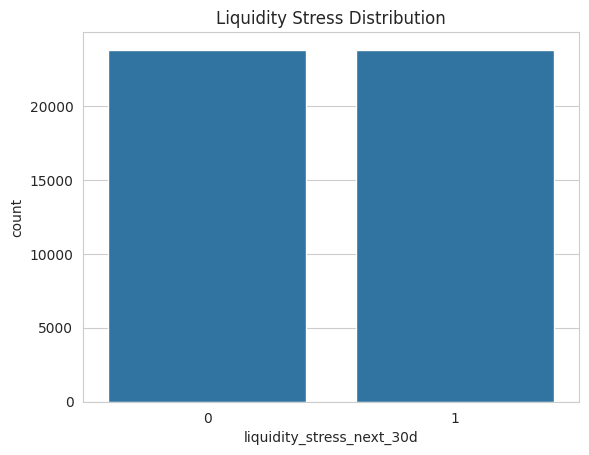

In [176]:
# Distribution of target variable
sns.countplot(x=y_oversampled)
plt.title("Liquidity Stress Distribution")
plt.show()


In [177]:
import pandas as pd

# 1. Calculate correlation with y_oversampled and convert to a DataFrame
correlation_df2 = X_oversampled.corrwith(y_oversampled).to_frame(name='Correlation')

# 2. Sort by absolute correlation (using correlation_df2) while keeping the original signed value
correlation_df2 = (
    correlation_df2
    .assign(Abs_Correlation=correlation_df2['Correlation'].abs()) # Fixed variable name here
    .sort_values(by='Abs_Correlation', ascending=False)
    .drop(columns=['Abs_Correlation'])
)

# Display the DataFrame
correlation_df2

,Correlation
m1_deposit_agents,-0.131336
m2_deposit_agents,-0.127291
m1_deposit_volume,-0.124246
m3_deposit_volume,-0.119110
m2_deposit_volume,-0.116021
...,...
region_Western Zone,0.001811
m1_transfer_from_bank_total_value,0.001692
age,0.001371
m1_mm_send_recipients,-0.000547


The caveat here is that correlation only measures linear relationships lets use tree-based models to identify which models are most important.

In [178]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
from sklearn.preprocessing import StandardScaler

## Scaler the data
scaler = StandardScaler()
X_oversampled_scaled = scaler.fit_transform(X_oversampled)


# Train a quick random forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_oversampled_scaled, y_oversampled)

# Get importances into a DataFrame
importance_df = pd.DataFrame({
    'Feature': X_oversampled.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

importance_df.head(25)

,Feature,Importance
133,smartphone_Yes,0.038738
137,earning_pattern_Weekly Earner,0.033869
126,gender_M,0.029665
127,region_Coastal & Eastern Corridor,0.026451
136,earning_pattern_Monthly Earner,0.025135
131,region_Southern Highlands,0.021298
88,m1_deposit_agents,0.018354
112,m3_withdraw_agents,0.018110
106,m1_withdraw_agents,0.015959
91,m2_deposit_agents,0.015951


In [179]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

In [180]:
# 2. Fit transform ONLY on the categorical training columns
val_encoded_array = ohe.transform(X_val[cat_cols])

# 3. Get the new feature names generated by OHE
encoded_feature_names = ohe.get_feature_names_out(cat_cols)

# 4. Convert the NumPy array back into a pandas DataFrame
X_val_encoded = pd.DataFrame(
    val_encoded_array,
    columns=encoded_feature_names,
    index=X_val.index
)

X_val_encoded.head()



,gender_M,region_Coastal & Eastern Corridor,region_Islander,region_Lake Zone (Northwest),region_Northern Highlands,region_Southern Highlands,region_Western Zone,smartphone_Yes,segment_LVC,segment_MVC,earning_pattern_Monthly Earner,earning_pattern_Weekly Earner
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
21133,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
10197,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
6895,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
7114,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


In [181]:
# 3. Drop the old unencoded categorical columns from X_train,
# and concatenate the new OHE columns alongside the numeric ones
X_val_ohe = pd.concat(
    [X_val.drop(columns=cat_cols), X_val_encoded],
    axis=1
)

X_val_ohe.head()

,arpu,age,x_90_d_activity_rate,m1_paybill_volume,m1_paybill_total_value,m1_paybill_highest_amount,m1_paybill_companies,m2_paybill_volume,m2_paybill_total_value,m2_paybill_highest_amount,m2_paybill_companies,m3_paybill_volume,m3_paybill_total_value,m3_paybill_highest_amount,m3_paybill_companies,m4_paybill_volume,m4_paybill_total_value,m4_paybill_highest_amount,m4_paybill_companies,m5_paybill_volume,m5_paybill_total_value,m5_paybill_highest_amount,m5_paybill_companies,m6_paybill_volume,m6_paybill_total_value,m6_paybill_highest_amount,m6_paybill_companies,m1_merchantpay_volume,m1_merchantpay_total_value,m1_merchantpay_highest_amount,m1_merchantpay_merchants,m2_merchantpay_volume,m2_merchantpay_total_value,m2_merchantpay_highest_amount,m2_merchantpay_merchants,m3_merchantpay_volume,m3_merchantpay_total_value,m3_merchantpay_highest_amount,m3_merchantpay_merchants,m4_merchantpay_volume,m4_merchantpay_total_value,m4_merchantpay_highest_amount,m4_merchantpay_merchants,m5_merchantpay_volume,m5_merchantpay_total_value,m5_merchantpay_highest_amount,m5_merchantpay_merchants,m6_merchantpay_volume,m6_merchantpay_total_value,m6_merchantpay_highest_amount,m6_merchantpay_merchants,m1_transfer_from_bank_volume,m1_transfer_from_bank_total_value,m1_transfer_from_bank_highest_amount,m1_transfer_from_bank_banks,m2_transfer_from_bank_volume,m2_transfer_from_bank_total_value,m2_transfer_from_bank_highest_amount,m2_transfer_from_bank_banks,m3_transfer_from_bank_volume,m3_transfer_from_bank_total_value,m3_transfer_from_bank_highest_amount,m3_transfer_from_bank_banks,m4_transfer_from_bank_volume,m4_transfer_from_bank_total_value,m4_transfer_from_bank_highest_amount,m4_transfer_from_bank_banks,m5_transfer_from_bank_volume,m5_transfer_from_bank_total_value,m5_transfer_from_bank_highest_amount,m5_transfer_from_bank_banks,m6_transfer_from_bank_volume,m6_transfer_from_bank_total_value,m6_transfer_from_bank_highest_amount,m6_transfer_from_bank_banks,m1_mm_send_volume,m1_mm_send_total_value,m1_mm_send_highest_amount,m1_mm_send_recipients,m2_mm_send_volume,m2_mm_send_total_value,m2_mm_send_highest_amount,m2_mm_send_recipients,m3_mm_send_volume,m3_mm_send_total_value,m3_mm_send_highest_amount,m3_mm_send_recipients,m4_mm_send_volume,m4_mm_send_total_value,m4_mm_send_highest_amount,m4_mm_send_recipients,m5_mm_send_volume,m5_mm_send_total_value,m5_mm_send_highest_amount,m5_mm_send_recipients,m6_mm_send_volume,m6_mm_send_total_value,m6_mm_send_highest_amount,m6_mm_send_recipients,m1_received_volume,m1_received_total_value,m1_received_highest_amount,m1_received_senders,m2_received_volume,m2_received_total_value,m2_received_highest_amount,m2_received_senders,m3_received_volume,m3_received_total_value,m3_received_highest_amount,m3_received_senders,m4_received_volume,m4_received_total_value,m4_received_highest_amount,m4_received_senders,m5_received_volume,m5_received_total_value,m5_received_highest_amount,m5_received_senders,m6_received_volume,m6_received_total_value,m6_received_highest_amount,m6_received_senders,m1_deposit_volume,m1_deposit_total_value,m1_deposit_highest_amount,m1_deposit_agents,m2_deposit_volume,m2_deposit_total_value,m2_deposit_highest_amount,m2_deposit_agents,m3_deposit_volume,m3_deposit_total_value,m3_deposit_highest_amount,m3_deposit_agents,m4_deposit_volume,m4_deposit_total_value,m4_deposit_highest_amount,m4_deposit_agents,m5_deposit_volume,m5_deposit_total_value,m5_deposit_highest_amount,m5_deposit_agents,m6_deposit_volume,m6_deposit_total_value,m6_deposit_highest_amount,m6_deposit_agents,m1_withdraw_volume,m1_withdraw_total_value,m1_withdraw_highest_amount,m1_withdraw_agents,m2_withdraw_volume,m2_withdraw_total_value,m2_withdraw_highest_amount,m2_withdraw_agents,m3_withdraw_volume,m3_withdraw_total_value,m3_withdraw_highest_amount,m3_withdraw_agents,m4_withdraw_volume,m4_withdraw_total_value,m4_withdraw_highest_amount,m4_withdraw_agents,m5_withdraw_volume,m5_withdraw_total_value,m5_withdraw_highest_amount,m5_withdraw_agents,m6_withdraw_volume,m

In [182]:
X_val_ohe.shape

(12000, 189)

In [183]:
X_val_ohe_adj=X_val_ohe.drop(columns=features_to_drop)
X_val_ohe_adj.head()

,age,x_90_d_activity_rate,m1_paybill_total_value,m1_paybill_highest_amount,m1_paybill_companies,m2_paybill_total_value,m2_paybill_highest_amount,m2_paybill_companies,m3_paybill_total_value,m3_paybill_highest_amount,m3_paybill_companies,m4_paybill_total_value,m4_paybill_highest_amount,m4_paybill_companies,m5_paybill_total_value,m5_paybill_highest_amount,m5_paybill_companies,m6_paybill_total_value,m6_paybill_highest_amount,m6_paybill_companies,m1_merchantpay_highest_amount,m1_merchantpay_merchants,m2_merchantpay_total_value,m2_merchantpay_merchants,m3_merchantpay_total_value,m3_merchantpay_merchants,m4_merchantpay_total_value,m4_merchantpay_merchants,m5_merchantpay_highest_amount,m5_merchantpay_merchants,m6_merchantpay_highest_amount,m6_merchantpay_merchants,m1_transfer_from_bank_total_value,m1_transfer_from_bank_highest_amount,m1_transfer_from_bank_banks,m2_transfer_from_bank_total_value,m2_transfer_from_bank_highest_amount,m2_transfer_from_bank_banks,m3_transfer_from_bank_volume,m3_transfer_from_bank_total_value,m3_transfer_from_bank_banks,m4_transfer_from_bank_total_value,m4_transfer_from_bank_highest_amount,m4_transfer_from_bank_banks,m5_transfer_from_bank_total_value,m5_transfer_from_bank_highest_amount,m5_transfer_from_bank_banks,m6_transfer_from_bank_total_value,m6_transfer_from_bank_highest_amount,m6_transfer_from_bank_banks,m1_mm_send_volume,m1_mm_send_total_value,m1_mm_send_recipients,m2_mm_send_total_value,m2_mm_send_highest_amount,m2_mm_send_recipients,m3_mm_send_volume,m3_mm_send_total_value,m3_mm_send_recipients,m4_mm_send_total_value,m4_mm_send_highest_amount,m4_mm_send_recipients,m5_mm_send_total_value,m5_mm_send_highest_amount,m5_mm_send_recipients,m6_mm_send_total_value,m6_mm_send_highest_amount,m6_mm_send_recipients,m1_received_volume,m1_received_total_value,m1_received_senders,m2_received_volume,m2_received_total_value,m2_received_senders,m3_received_volume,m3_received_total_value,m3_received_senders,m4_received_total_value,m4_received_highest_amount,m4_received_senders,m5_received_total_value,m5_received_highest_amount,m5_received_senders,m6_received_total_value,m6_received_highest_amount,m6_received_senders,m1_deposit_volume,m1_deposit_total_value,m1_deposit_agents,m2_deposit_volume,m2_deposit_total_value,m2_deposit_agents,m3_deposit_volume,m3_deposit_total_value,m3_deposit_agents,m4_deposit_total_value,m4_deposit_highest_amount,m4_deposit_agents,m5_deposit_total_value,m5_deposit_highest_amount,m5_deposit_agents,m6_deposit_total_value,m6_deposit_highest_amount,m6_deposit_agents,m1_withdraw_volume,m1_withdraw_total_value,m1_withdraw_agents,m2_withdraw_volume,m2_withdraw_total_value,m2_withdraw_agents,m3_withdraw_volume,m3_withdraw_total_value,m3_withdraw_agents,m4_withdraw_volume,m4_withdraw_total_value,m4_withdraw_agents,m5_withdraw_total_value,m5_withdraw_highest_amount,m5_withdraw_agents,m6_withdraw_volume,m6_withdraw_total_value,m6_withdraw_agents,m1_daily_avg_bal,m4_daily_avg_bal,m5_daily_avg_bal,m6_daily_avg_bal,gender_M,region_Coastal & Eastern Corridor,region_Islander,region_Lake Zone (Northwest),region_Northern Highlands,region_Southern Highlands,region_Western Zone,smartphone_Yes,segment_LVC,segment_MVC,earning_pattern_Monthly Earner,earning_pattern_Weekly Earner
3,47,0.6905,8738.58,4472.39,7.0,0.00,0.00,0.0,29229.38,3515.18,2.0,29278.83,3131.64,8.0,6715.94,4295.42,2.0,0.00,0.00,0.0,0.00,0.0,0.00,0.0,2526.83,14.0,3597.64,12.0,0.00,0.0,1591.74,1.0,0.00,0.00,0.0,6363.58,3534.06,10.0,0,0.00,0.0,0.0,0.0,0.0,6362.51,6126.81,4.0,7943.67,6891.6,11.0,5,21330.28,6.0,102638.93,9608.10,7.0,0,0.00,0.0,30562.36,10103.09,9.0,71863.60,3677.83,14.0,26021.37,7335.93,11.0,0,0.00,0.0,0,0.00,0.0,16,167256.29,16.0,0.00,0.00,0.0,0.0,0.0,0.0,102464.84,8712.82,13.0,0,0.00,0.0,12,96043.44,2.0,8,167902.17,3.0,0.00,0.00,0.0,0.00,0.00,0.0,261151.28,10928.59,2.0,0,0.00,0.0,11,72260.50,4.0,13,115874.33,2.0,12,131327.65,2.0,0.00,0.00,0.0,11,98268.75,3.0,14331.10,3577.07,18990.91,8488.26,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.

In [184]:
# Make predictions

y_train_pred=rf.predict(X_oversampled_scaled)

## scale and predict validation data
X_val_ohe_adj_scaled = scaler.transform(X_val_ohe_adj)
y_val_pred=rf.predict(X_val_ohe_adj_scaled)

# Training set performance
model_train_accuracy=accuracy_score(y_oversampled,y_train_pred)
model_train_f1=f1_score(y_oversampled,y_train_pred, average='weighted')
model_train_precision=precision_score(y_oversampled,y_train_pred)
model_train_recall=recall_score(y_oversampled,y_train_pred)
model_train_rocauc_score=roc_auc_score(y_oversampled,y_train_pred)

# Testing set performance
model_val_accuracy=accuracy_score(y_val,y_val_pred)
model_val_f1=f1_score(y_val,y_val_pred, average='weighted')
model_val_precision=precision_score(y_val,y_val_pred)
model_val_recall=recall_score(y_val,y_val_pred)
model_val_rocauc_score=roc_auc_score(y_val,y_val_pred)


print("Random Forest Classifier Model Performance")
print("----------------------------------------------------------------------")

print('Model performance for Training set')
print('- Accuracy: {:.4f}'.format(model_train_accuracy))
print('- F1 score: {:.4f}'.format(model_train_f1))
print('- Precision: {:.4f}'.format(model_train_precision))
print('- Recall: {:.4f}'.format(model_train_recall))
print('- Roc Auc Score: {:.4f}'.format(model_train_rocauc_score))

print('-----------------------------------')

print('Model performance for Test set')
print('-Accuracy: {:.4f}'.format(model_val_accuracy))
print('- F1 score: {:.4f}'.format(model_val_f1))
print('- Precision: {:.4f}'.format(model_val_precision))
print('- Recall: {:.4f}'.format(model_val_recall))
print('- Roc Auc Score: {:.4f}'.format(model_val_rocauc_score))

Random Forest Classifier Model Performance
----------------------------------------------------------------------
Model performance for Training set
- Accuracy: 1.0000
- F1 score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- Roc Auc Score: 1.0000
-----------------------------------
Model performance for Test set
-Accuracy: 0.8543
- F1 score: 0.7955
- Precision: 0.7364
- Recall: 0.0450
- Roc Auc Score: 0.5211


This shows heavy overfitting acros board

What the numbers say

**Test ROC AUC of 0.518** is essentially a coin flip. The model can’t rank positives above negatives on unseen data.
* Accuracy of 0.853 is just the majority-class rate. Predicting 0 for everyone would score about the same.
* Recall of 0.039 means it catches about 4% of class 1. The precision and F1 you printed look like weighted averages across both classes, which is why they seem high next to that recall. Look at the class-1 row of classification_report.
* Train score of 1.0 is expected, not a bug. A fully grown forest on SMOTE-balanced data memorizes the training set. It only tells you the model has capacity, not that it learned anything real.

**What it means: the features, as currently built, carry little generalizable signal for this target. No threshold change will fix an AUC of 0.52.**

In [185]:
# Predict on validation set
val_pred_prob = rf.predict_proba(X_val_ohe_adj_scaled)[:, 1]
val_pred_label = (val_pred_prob >= 0.5).astype(int)

# Evaluate
print("Validation ROC-AUC:", roc_auc_score(y_val, val_pred_prob))
print("\nClassification Report:")
print(classification_report(y_val, val_pred_label))


Validation ROC-AUC: 0.7134340958605665

Classification Report:
              precision    recall  f1-score   support

           0       0.86      1.00      0.92     10200
           1       0.72      0.05      0.10      1800

    accuracy                           0.85     12000
   macro avg       0.79      0.52      0.51     12000
weighted avg       0.84      0.85      0.80     12000



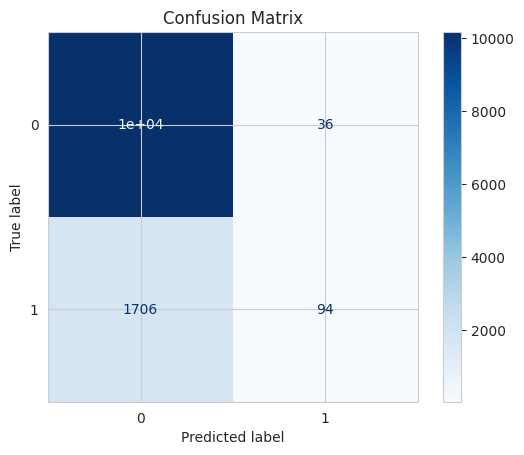

In [186]:
# 📈 Evaluate Model on Validation Set
cm = confusion_matrix(y_val, val_pred_label)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

This is problematic. Randomly predicting 0 is 85% correct. From the overfitting we can see that the model literally learned nothing giving how poorly it performed predicting the 1s(`recall` performance).

Next step let us try seeing if the performance will improve without oversampling

In [187]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
from sklearn.preprocessing import StandardScaler

## Scaler the data
scaler2 = StandardScaler()
X_train_ohe_adj_scaled = scaler2.fit_transform(X_train_ohe_adj)


# Train a quick random forest
rf2 = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=20,
                          max_features="sqrt", class_weight="balanced_subsample",
                          n_jobs=-1, random_state=42)

rf2.fit(X_train_ohe_adj_scaled, y_train)

# Get importances into a DataFrame
importance_df = pd.DataFrame({
    'Feature': X_train_ohe_adj.columns,
    'Importance': rf2.feature_importances_
}).sort_values(by='Importance', ascending=False)

importance_df.head(25)

,Feature,Importance
123,m4_daily_avg_bal,0.043685
125,m6_daily_avg_bal,0.042306
90,m2_deposit_total_value,0.041220
124,m5_daily_avg_bal,0.036502
87,m1_deposit_total_value,0.034677
93,m3_deposit_total_value,0.034377
122,m1_daily_avg_bal,0.030399
89,m2_deposit_volume,0.025787
86,m1_deposit_volume,0.024376
72,m2_received_total_value,0.023088


In [188]:
# Make predictions

y_train_pred=rf2.predict(X_train_ohe_adj_scaled)

## scale and predict validation data
X_val_ohe_adj_scaled = scaler2.transform(X_val_ohe_adj)
y_val_pred=rf2.predict(X_val_ohe_adj_scaled)

# Training set performance
model_train_accuracy=accuracy_score(y_train,y_train_pred)
model_train_f1=f1_score(y_train,y_train_pred, average='weighted')
model_train_precision=precision_score(y_train,y_train_pred)
model_train_recall=recall_score(y_train,y_train_pred)
model_train_rocauc_score=roc_auc_score(y_train,y_train_pred)

# Testing set performance
model_val_accuracy=accuracy_score(y_val,y_val_pred)
model_val_f1=f1_score(y_val,y_val_pred, average='weighted')
model_val_precision=precision_score(y_val,y_val_pred)
model_val_recall=recall_score(y_val,y_val_pred)
model_val_rocauc_score=roc_auc_score(y_val,y_val_pred)


print("Random Forest Classifier Model Performance")
print("----------------------------------------------------------------------")

print('Model performance for Training set')
print('- Accuracy: {:.4f}'.format(model_train_accuracy))
print('- F1 score: {:.4f}'.format(model_train_f1))
print('- Precision: {:.4f}'.format(model_train_precision))
print('- Recall: {:.4f}'.format(model_train_recall))
print('- Roc Auc Score: {:.4f}'.format(model_train_rocauc_score))

print('-----------------------------------')

print('Model performance for Test set')
print('-Accuracy: {:.4f}'.format(model_val_accuracy))
print('- F1 score: {:.4f}'.format(model_val_f1))
print('- Precision: {:.4f}'.format(model_val_precision))
print('- Recall: {:.4f}'.format(model_val_recall))
print('- Roc Auc Score: {:.4f}'.format(model_val_rocauc_score))

Random Forest Classifier Model Performance
----------------------------------------------------------------------
Model performance for Training set
- Accuracy: 0.8553
- F1 score: 0.8642
- Precision: 0.5128
- Recall: 0.7050
- Roc Auc Score: 0.7934
-----------------------------------
Model performance for Test set
-Accuracy: 0.8065
- F1 score: 0.8172
- Precision: 0.3906
- Recall: 0.5178
- Roc Auc Score: 0.6876


In [189]:
# Predict on validation set
val_pred_prob = rf2.predict_proba(X_val_ohe_adj_scaled)[:, 1]
val_pred_label = (val_pred_prob >= 0.5).astype(int)

# Evaluate
print("Validation ROC-AUC:", roc_auc_score(y_val, val_pred_prob))
print("\nClassification Report:")
print(classification_report(y_val, val_pred_label))


Validation ROC-AUC: 0.7690181372549019

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.86      0.88     10200
           1       0.39      0.52      0.45      1800

    accuracy                           0.81     12000
   macro avg       0.65      0.69      0.66     12000
weighted avg       0.83      0.81      0.82     12000



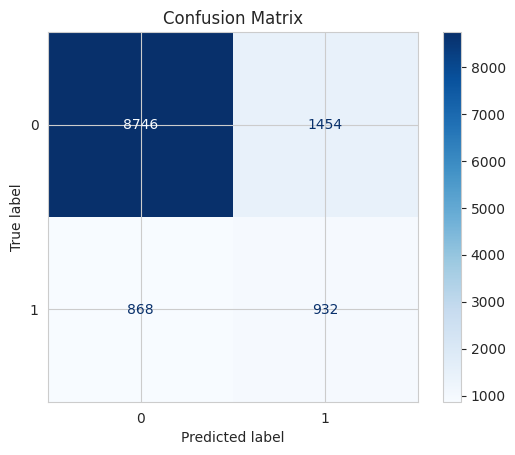

In [190]:
# 📈 Evaluate Model on Validation Set
cm = confusion_matrix(y_val, val_pred_label)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

Let us see the ROC-AUC curve.

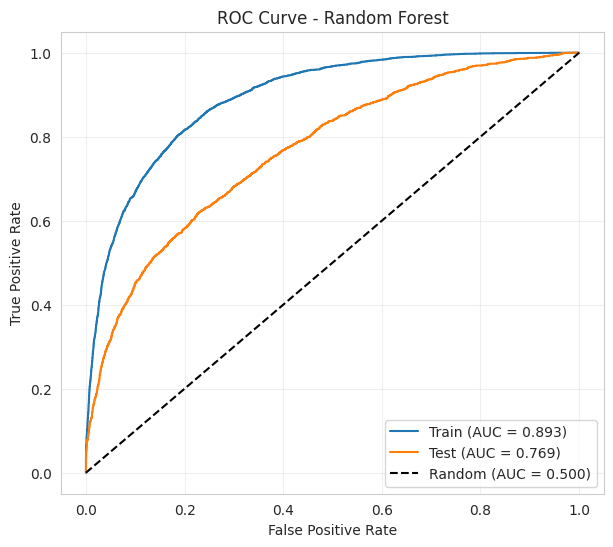

In [191]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Probabilities for class 1
train_prob = rf2.predict_proba(X_train_ohe_adj_scaled)[:, 1]
test_prob = rf2.predict_proba(X_val_ohe_adj_scaled)[:, 1]

# ROC curves
fpr_tr, tpr_tr, _ = roc_curve(y_train, train_prob)
fpr_te, tpr_te, _ = roc_curve(y_val, test_prob)

plt.figure(figsize=(7, 6))
plt.plot(fpr_tr, tpr_tr, label=f"Train (AUC = {roc_auc_score(y_train, train_prob):.3f})")
plt.plot(fpr_te, tpr_te, label=f"Test (AUC = {roc_auc_score(y_val, test_prob):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

We have already done the grid search below and have discovered the best models are LightGBM, Catboost and ANN. We will reproduce LightGBM and Catboost here.

## Grid Search
We will run grid search for tree based models

In [ ]:
# from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
# from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
# from sklearn.linear_model import LogisticRegression
# from sklearn.tree import DecisionTreeClassifier

In [ ]:
%pip install catboost

In [ ]:
import numpy as np
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
)
from sklearn.svm import SVC
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier


In [ ]:

RANDOM_STATE = 42

# verbose removed from the estimators: with CV it prints thousands of lines.
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE),
    "SVC": SVC(random_state=RANDOM_STATE, cache_size=1000),
    "LightGBM": LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
    "CatBoost": CatBoostClassifier(random_state=RANDOM_STATE, thread_count=-1, verbose=0),
}

params = {
    "Decision Tree": {
        "criterion": ["gini", "entropy"],
        "max_depth": [5, 8, 12],
        "min_samples_leaf": [10, 20, 50],
        "max_features": ["sqrt", None],
        "class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "n_estimators": [200, 300],
        "max_depth": [8, 12],
        "min_samples_leaf": [10, 20, 50],
        "max_features": ["sqrt"],
        "class_weight": ["balanced_subsample", None],
    },
    "Gradient Boosting": {
        "learning_rate": [0.05, 0.1],
        "n_estimators": [100, 200],
        "max_depth": [3, 5],
        "max_features": ["sqrt", None],
    },
    "Logistic Regression": {
        "C": [0.1, 1, 10],
        "penalty": ["l2"],
        "solver": ["lbfgs"],
        "class_weight": [None, "balanced"],
    },
    "AdaBoost": {
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.1, 1.0],
    },
    "SVC": { ## SVC will take too much time
        "C": [0.1, 1],
        "kernel": ["rbf"],
        "gamma": ["scale"],
        "class_weight": [None, "balanced"],
    },
    "KNN": {
        "n_neighbors": [15, 31, 51, 101],
        "weights": ["uniform", "distance"],
        "p": [1, 2],                      # 1 = Manhattan, 2 = Euclidean
    },
    "LightGBM": {
        "num_leaves": [15, 31],
        "learning_rate": [0.05, 0.1],
        "n_estimators": [200, 400],
        "class_weight": [None, "balanced"],
    },

    "CatBoost": {
        "depth": [4, 6],
        "learning_rate": [0.05, 0.1],
        "iterations": [200, 400],
        "auto_class_weights": ["None", "Balanced"],
    },
}


In [ ]:
## models list for Hyperparameter tuning
randomcv_models=[
    ("Decision Tree", DecisionTreeClassifier(random_state=RANDOM_STATE),params['Decision Tree']),
    ("Random Forest", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),params['Random Forest']),
    ("Gradient Boosting", GradientBoostingClassifier(random_state=RANDOM_STATE),params['Gradient Boosting']),
    ("Logistic Regression", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),params['Logistic Regression']),
    ("AdaBoost", AdaBoostClassifier(random_state=RANDOM_STATE),params['AdaBoost']),
    ("SVC", SVC(random_state=RANDOM_STATE, cache_size=1000), params['SVC']), ## This will take too much time
    ("LightGBM", LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1), params['LightGBM']),
    ("CatBoost", CatBoostClassifier(random_state=RANDOM_STATE, thread_count=-1, verbose=0), params['CatBoost']),
    ("KNN", KNeighborsClassifier(n_jobs=-1), params["KNN"]),
]


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

model_param={}
for name, model, params in randomcv_models:
    random=RandomizedSearchCV(
        estimator=model,
        param_distributions=params,
        n_iter=100,
        cv=3,
        verbose=2,
        n_jobs=-1
    )
    random.fit(X_train_ohe_adj_scaled,y_train) ## Note we are not using oversampled data
    model_param[name]=random.best_params_

for model_name in model_param:
    print(f'______________ Best Params for {model_name} _________________')
    print (model_param[model_name])

Grid search completed. Only catboost and SVM were not successful and executed respectively. We will run them alone in another grid search.

The best params are:

* ______________ Best Params for Decision Tree _________________
{'min_samples_leaf': 50, 'max_features': None, 'max_depth': 12, 'criterion': 'gini', 'class_weight': None}
* ______________ Best Params for Random Forest _________________
{'n_estimators': 300, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 12, 'class_weight': 'balanced_subsample'}
* ______________ Best Params for Gradient Boosting _________________
{'n_estimators': 200, 'max_features': None, 'max_depth': 5, 'learning_rate': 0.1}
* ______________ Best Params for Logistic Regression _________________
{'solver': 'lbfgs', 'penalty': 'l2', 'class_weight': None, 'C': 10}
* ______________ Best Params for AdaBoost _________________
{'n_estimators': 200, 'learning_rate': 1.0}
* ______________ Best Params for LightGBM _________________
{'num_leaves': 31, 'n_estimators': 400, 'learning_rate': 0.05, 'class_weight': None}
* ______________ Best Params for CatBoost _________________
{'learning_rate': 0.1, 'iterations': 400, 'depth': 6, 'auto_class_weights': 'Balanced'}

In [ ]:
from sklearn.base import clone
import pandas as pd
from sklearn.metrics import (accuracy_score, roc_auc_score,
                             classification_report, confusion_matrix)

results = []
fitted_models = {}

for model_name, model, _ in randomcv_models:
    print(f"{model_name} training")

    # fresh copy of the estimator with the tuned params applied
    model_obj = clone(model).set_params(**model_param[model_name])
    model_obj.fit(X_train_ohe_adj_scaled, y_train)
    fitted_models[model_name] = model_obj

    # probabilities and labels
    train_prob = model_obj.predict_proba(X_train_ohe_adj_scaled)[:, 1]
    val_prob = model_obj.predict_proba(X_val_ohe_adj_scaled)[:, 1]
    val_pred = (val_prob >= 0.5).astype(int)
    train_pred = (train_prob >= 0.5).astype(int)

    train_auc = roc_auc_score(y_train, train_prob)
    val_auc = roc_auc_score(y_val, val_prob)
    rep = classification_report(y_val, val_pred, output_dict=True)

    print(f"Train ROC-AUC: {train_auc:.4f} | Validation ROC-AUC: {val_auc:.4f}")
    print(f"Train accuracy: {accuracy_score(y_train, train_pred):.4f} | "
          f"Validation accuracy: {accuracy_score(y_val, val_pred):.4f}")
    print(classification_report(y_val, val_pred))
    print(confusion_matrix(y_val, val_pred))
    print("\n" + "-" * 60 + "\n")

    results.append({
        "model": model_name,
        "train_auc": train_auc,
        "val_auc": val_auc,
        "auc_gap": train_auc - val_auc,
        "val_precision_1": rep["1"]["precision"],
        "val_recall_1": rep["1"]["recall"],
        "val_f1_1": rep["1"]["f1-score"],
    })

results_df = pd.DataFrame(results).sort_values("val_auc", ascending=False)
results_df

Lets do the grid search for catboost and SVC again. Just the 2 of them

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

model_to_train=['SVC', 'CatBoost','KNN']
model_param={}
for name, model, params in randomcv_models:
  if name in model_to_train:
    print(f'Training {name}')
    random=RandomizedSearchCV(
        estimator=model,
        param_distributions=params,
        n_iter=100,
        cv=3,
        verbose=2,
        n_jobs=-1
    )
    random.fit(X_train_ohe_adj_scaled,y_train) ## Note we are not using oversampled data
    model_param[name]=random.best_params_

for model_name in model_param:
    print(f'______________ Best Params for {model_name} _________________')
    print (model_param[model_name])

The best params:

* ______________ Best Params for SVC _________________
{'kernel': 'rbf', 'gamma': 'scale', 'class_weight': None, 'C': 0.1}
* ______________ Best Params for CatBoost _________________
{'learning_rate': 0.1, 'iterations': 400, 'depth': 6, 'auto_class_weights': 'None'}
* ______________ Best Params for KNN _________________
{'weights': 'uniform', 'p': 1, 'n_neighbors': 31}

Because SVC does not have predict_proba() attribute we will use decision_function() instead.

In [ ]:
def get_scores(model, X):
    """Return a continuous score for class 1, for any model."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

In [ ]:
from sklearn.base import clone
import pandas as pd
from sklearn.metrics import (accuracy_score, roc_auc_score,
                             classification_report, confusion_matrix)

model_to_train=['SVC', 'CatBoost','KNN']
results = []
fitted_models = {}

for model_name, model, _ in randomcv_models:
  if model_name in model_to_train:
    print(f"{model_name} training")

    # fresh copy of the estimator with the tuned params applied
    model_obj = clone(model).set_params(**model_param[model_name])
    model_obj.fit(X_train_ohe_adj_scaled, y_train)
    fitted_models[model_name] = model_obj

    # probabilities and labels
    train_prob = get_scores(model_obj, X_train_ohe_adj_scaled)
    val_prob = get_scores(model_obj, X_val_ohe_adj_scaled)
    # train_prob = model_obj.predict_proba(X_train_ohe_adj_scaled)[:, 1]
    # val_prob = model_obj.predict_proba(X_val_ohe_adj_scaled)[:, 1]

    val_pred = (val_prob >= 0.5).astype(int)
    train_pred = (train_prob >= 0.5).astype(int)

    train_auc = roc_auc_score(y_train, train_prob)
    val_auc = roc_auc_score(y_val, val_prob)
    rep = classification_report(y_val, val_pred, output_dict=True)

    print(f"Train ROC-AUC: {train_auc:.4f} | Validation ROC-AUC: {val_auc:.4f}")
    print(f"Train accuracy: {accuracy_score(y_train, train_pred):.4f} | "
          f"Validation accuracy: {accuracy_score(y_val, val_pred):.4f}")
    print(classification_report(y_val, val_pred))
    print(confusion_matrix(y_val, val_pred))
    print("\n" + "-" * 60 + "\n")

    results.append({
        "model": model_name,
        "train_auc": train_auc,
        "val_auc": val_auc,
        "auc_gap": train_auc - val_auc,
        "val_precision_1": rep["1"]["precision"],
        "val_recall_1": rep["1"]["recall"],
        "val_f1_1": rep["1"]["f1-score"],
    })

results_df = pd.DataFrame(results).sort_values("val_auc", ascending=False)
results_df

## Artificial Neural Network

We will use deep learning to see if we can get an improved performance especially when predicting the minority class

In [121]:
# 📚 Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, log_loss, precision_recall_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Input,BatchNormalization,Dropout
from tensorflow.keras.callbacks import EarlyStopping,TensorBoard, ReduceLROnPlateau
import datetime

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 200)


In [122]:
# 📥 Load the Data
train = pd.read_csv("Train.csv")
test = pd.read_csv("Test.csv")

SUBMISSION_TARGET = "Target"

# Create a sample submission template directly from the test IDs
sample_submission = pd.DataFrame({
    "ID": test["ID"],
    SUBMISSION_TARGET: 0.5
})

# Peek at the data
train.head()


,arpu,age,gender,region,smartphone,segment,earning_pattern,x_90_d_activity_rate,m1_paybill_volume,m1_paybill_total_value,m1_paybill_highest_amount,m1_paybill_companies,m2_paybill_volume,m2_paybill_total_value,m2_paybill_highest_amount,m2_paybill_companies,m3_paybill_volume,m3_paybill_total_value,m3_paybill_highest_amount,m3_paybill_companies,m4_paybill_volume,m4_paybill_total_value,m4_paybill_highest_amount,m4_paybill_companies,m5_paybill_volume,m5_paybill_total_value,m5_paybill_highest_amount,m5_paybill_companies,m6_paybill_volume,m6_paybill_total_value,m6_paybill_highest_amount,m6_paybill_companies,m1_merchantpay_volume,m1_merchantpay_total_value,m1_merchantpay_highest_amount,m1_merchantpay_merchants,m2_merchantpay_volume,m2_merchantpay_total_value,m2_merchantpay_highest_amount,m2_merchantpay_merchants,m3_merchantpay_volume,m3_merchantpay_total_value,m3_merchantpay_highest_amount,m3_merchantpay_merchants,m4_merchantpay_volume,m4_merchantpay_total_value,m4_merchantpay_highest_amount,m4_merchantpay_merchants,m5_merchantpay_volume,m5_merchantpay_total_value,m5_merchantpay_highest_amount,m5_merchantpay_merchants,m6_merchantpay_volume,m6_merchantpay_total_value,m6_merchantpay_highest_amount,m6_merchantpay_merchants,m1_transfer_from_bank_volume,m1_transfer_from_bank_total_value,m1_transfer_from_bank_highest_amount,m1_transfer_from_bank_banks,m2_transfer_from_bank_volume,m2_transfer_from_bank_total_value,m2_transfer_from_bank_highest_amount,m2_transfer_from_bank_banks,m3_transfer_from_bank_volume,m3_transfer_from_bank_total_value,m3_transfer_from_bank_highest_amount,m3_transfer_from_bank_banks,m4_transfer_from_bank_volume,m4_transfer_from_bank_total_value,m4_transfer_from_bank_highest_amount,m4_transfer_from_bank_banks,m5_transfer_from_bank_volume,m5_transfer_from_bank_total_value,m5_transfer_from_bank_highest_amount,m5_transfer_from_bank_banks,m6_transfer_from_bank_volume,m6_transfer_from_bank_total_value,m6_transfer_from_bank_highest_amount,m6_transfer_from_bank_banks,m1_mm_send_volume,m1_mm_send_total_value,m1_mm_send_highest_amount,m1_mm_send_recipients,m2_mm_send_volume,m2_mm_send_total_value,m2_mm_send_highest_amount,m2_mm_send_recipients,m3_mm_send_volume,m3_mm_send_total_value,m3_mm_send_highest_amount,m3_mm_send_recipients,m4_mm_send_volume,m4_mm_send_total_value,m4_mm_send_highest_amount,m4_mm_send_recipients,m5_mm_send_volume,m5_mm_send_total_value,m5_mm_send_highest_amount,m5_mm_send_recipients,m6_mm_send_volume,m6_mm_send_total_value,m6_mm_send_highest_amount,m6_mm_send_recipients,m1_received_volume,m1_received_total_value,m1_received_highest_amount,m1_received_senders,m2_received_volume,m2_received_total_value,m2_received_highest_amount,m2_received_senders,m3_received_volume,m3_received_total_value,m3_received_highest_amount,m3_received_senders,m4_received_volume,m4_received_total_value,m4_received_highest_amount,m4_received_senders,m5_received_volume,m5_received_total_value,m5_received_highest_amount,m5_received_senders,m6_received_volume,m6_received_total_value,m6_received_highest_amount,m6_received_senders,m1_deposit_volume,m1_deposit_total_value,m1_deposit_highest_amount,m1_deposit_agents,m2_deposit_volume,m2_deposit_total_value,m2_deposit_highest_amount,m2_deposit_agents,m3_deposit_volume,m3_deposit_total_value,m3_deposit_highest_amount,m3_deposit_agents,m4_deposit_volume,m4_deposit_total_value,m4_deposit_highest_amount,m4_deposit_agents,m5_deposit_volume,m5_deposit_total_value,m5_deposit_highest_amount,m5_deposit_agents,m6_deposit_volume,m6_deposit_total_value,m6_deposit_highest_amount,m6_deposit_agents,m1_withdraw_volume,m1_withdraw_total_value,m1_withdraw_highest_amount,m1_withdraw_agents,m2_withdraw_volume,m2_withdraw_total_value,m2_withdraw_highest_amount,m2_withdraw_agents,m3_withdraw_volume,m3_withdraw_total_value,m3_withdraw_highest_amount,m3_withdraw_agents,m4_withdraw_volume,m4_withdraw_total_value,m4_withdraw_highest_amount,m4_withdraw_agents,m5_withdraw_volume,m5_withdraw_total_value,m5_withdraw_highe

In [123]:
# Identify the ID column, target column and feature columns
TARGET = "liquidity_stress_next_30d"
ID_COL = "ID"

feature_cols = [c for c in train.columns if c not in [ID_COL, TARGET]]
cat_cols = [c for c in feature_cols if train[c].dtype == "object"]
num_cols = (
    train.select_dtypes(include=['number'])
    .drop(columns=[TARGET], errors='ignore')
    .columns.tolist()
)

cat_cols

['gender', 'region', 'smartphone', 'segment', 'earning_pattern']

In [124]:
X=train[feature_cols]
y=train[TARGET]

In [125]:
##split the data to train and validation
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, random_state=42)

In [126]:
# 1. Initialize the encoder (drop='first' mimics what you used before)
ohe = OneHotEncoder(drop='first', sparse_output=False)

# 2. Fit and transform ONLY on the categorical training columns
train_encoded_array = ohe.fit_transform(X_train[cat_cols])

# 3. Get the new feature names generated by OHE
encoded_feature_names = ohe.get_feature_names_out(cat_cols)

# 4. Convert the NumPy array back into a pandas DataFrame
X_train_encoded = pd.DataFrame(
    train_encoded_array,
    columns=encoded_feature_names,
    index=X_train.index
)

X_train_encoded.head()



,gender_M,region_Coastal & Eastern Corridor,region_Islander,region_Lake Zone (Northwest),region_Northern Highlands,region_Southern Highlands,region_Western Zone,smartphone_Yes,segment_LVC,segment_MVC,earning_pattern_Monthly Earner,earning_pattern_Weekly Earner
38015,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
2281,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
36629,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
6087,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
11792,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0


In [127]:
# 3. Drop the old unencoded categorical columns from X_train,
# and concatenate the new OHE columns alongside the numeric ones
X_train_ohe = pd.concat(
    [X_train.drop(columns=cat_cols), X_train_encoded],
    axis=1
)

X_train_ohe.head()

,arpu,age,x_90_d_activity_rate,m1_paybill_volume,m1_paybill_total_value,m1_paybill_highest_amount,m1_paybill_companies,m2_paybill_volume,m2_paybill_total_value,m2_paybill_highest_amount,m2_paybill_companies,m3_paybill_volume,m3_paybill_total_value,m3_paybill_highest_amount,m3_paybill_companies,m4_paybill_volume,m4_paybill_total_value,m4_paybill_highest_amount,m4_paybill_companies,m5_paybill_volume,m5_paybill_total_value,m5_paybill_highest_amount,m5_paybill_companies,m6_paybill_volume,m6_paybill_total_value,m6_paybill_highest_amount,m6_paybill_companies,m1_merchantpay_volume,m1_merchantpay_total_value,m1_merchantpay_highest_amount,m1_merchantpay_merchants,m2_merchantpay_volume,m2_merchantpay_total_value,m2_merchantpay_highest_amount,m2_merchantpay_merchants,m3_merchantpay_volume,m3_merchantpay_total_value,m3_merchantpay_highest_amount,m3_merchantpay_merchants,m4_merchantpay_volume,m4_merchantpay_total_value,m4_merchantpay_highest_amount,m4_merchantpay_merchants,m5_merchantpay_volume,m5_merchantpay_total_value,m5_merchantpay_highest_amount,m5_merchantpay_merchants,m6_merchantpay_volume,m6_merchantpay_total_value,m6_merchantpay_highest_amount,m6_merchantpay_merchants,m1_transfer_from_bank_volume,m1_transfer_from_bank_total_value,m1_transfer_from_bank_highest_amount,m1_transfer_from_bank_banks,m2_transfer_from_bank_volume,m2_transfer_from_bank_total_value,m2_transfer_from_bank_highest_amount,m2_transfer_from_bank_banks,m3_transfer_from_bank_volume,m3_transfer_from_bank_total_value,m3_transfer_from_bank_highest_amount,m3_transfer_from_bank_banks,m4_transfer_from_bank_volume,m4_transfer_from_bank_total_value,m4_transfer_from_bank_highest_amount,m4_transfer_from_bank_banks,m5_transfer_from_bank_volume,m5_transfer_from_bank_total_value,m5_transfer_from_bank_highest_amount,m5_transfer_from_bank_banks,m6_transfer_from_bank_volume,m6_transfer_from_bank_total_value,m6_transfer_from_bank_highest_amount,m6_transfer_from_bank_banks,m1_mm_send_volume,m1_mm_send_total_value,m1_mm_send_highest_amount,m1_mm_send_recipients,m2_mm_send_volume,m2_mm_send_total_value,m2_mm_send_highest_amount,m2_mm_send_recipients,m3_mm_send_volume,m3_mm_send_total_value,m3_mm_send_highest_amount,m3_mm_send_recipients,m4_mm_send_volume,m4_mm_send_total_value,m4_mm_send_highest_amount,m4_mm_send_recipients,m5_mm_send_volume,m5_mm_send_total_value,m5_mm_send_highest_amount,m5_mm_send_recipients,m6_mm_send_volume,m6_mm_send_total_value,m6_mm_send_highest_amount,m6_mm_send_recipients,m1_received_volume,m1_received_total_value,m1_received_highest_amount,m1_received_senders,m2_received_volume,m2_received_total_value,m2_received_highest_amount,m2_received_senders,m3_received_volume,m3_received_total_value,m3_received_highest_amount,m3_received_senders,m4_received_volume,m4_received_total_value,m4_received_highest_amount,m4_received_senders,m5_received_volume,m5_received_total_value,m5_received_highest_amount,m5_received_senders,m6_received_volume,m6_received_total_value,m6_received_highest_amount,m6_received_senders,m1_deposit_volume,m1_deposit_total_value,m1_deposit_highest_amount,m1_deposit_agents,m2_deposit_volume,m2_deposit_total_value,m2_deposit_highest_amount,m2_deposit_agents,m3_deposit_volume,m3_deposit_total_value,m3_deposit_highest_amount,m3_deposit_agents,m4_deposit_volume,m4_deposit_total_value,m4_deposit_highest_amount,m4_deposit_agents,m5_deposit_volume,m5_deposit_total_value,m5_deposit_highest_amount,m5_deposit_agents,m6_deposit_volume,m6_deposit_total_value,m6_deposit_highest_amount,m6_deposit_agents,m1_withdraw_volume,m1_withdraw_total_value,m1_withdraw_highest_amount,m1_withdraw_agents,m2_withdraw_volume,m2_withdraw_total_value,m2_withdraw_highest_amount,m2_withdraw_agents,m3_withdraw_volume,m3_withdraw_total_value,m3_withdraw_highest_amount,m3_withdraw_agents,m4_withdraw_volume,m4_withdraw_total_value,m4_withdraw_highest_amount,m4_withdraw_agents,m5_withdraw_volume,m5_withdraw_total_value,m5_withdraw_highest_amount,m5_withdraw_agents,m6_withdraw_volume,m

In [128]:
X_train_ohe.shape

(28000, 189)

In [129]:
## standardize the data
scaler = StandardScaler()
X_train_ohe_scaled = scaler.fit_transform(X_train_ohe)

In [130]:
y_train.shape

(28000,)

In [131]:
# 2. Fit transform ONLY on the categorical training columns
val_encoded_array = ohe.transform(X_val[cat_cols])

# 3. Get the new feature names generated by OHE
encoded_feature_names = ohe.get_feature_names_out(cat_cols)

# 4. Convert the NumPy array back into a pandas DataFrame
X_val_encoded = pd.DataFrame(
    val_encoded_array,
    columns=encoded_feature_names,
    index=X_val.index
)

X_val_encoded.head()

,gender_M,region_Coastal & Eastern Corridor,region_Islander,region_Lake Zone (Northwest),region_Northern Highlands,region_Southern Highlands,region_Western Zone,smartphone_Yes,segment_LVC,segment_MVC,earning_pattern_Monthly Earner,earning_pattern_Weekly Earner
32823,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
16298,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
28505,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
6689,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
26893,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0


In [132]:
# 3. Drop the old unencoded categorical columns from X_train,
# and concatenate the new OHE columns alongside the numeric ones
X_val_ohe = pd.concat(
    [X_val.drop(columns=cat_cols), X_val_encoded],
    axis=1
)

X_val_ohe.head()

,arpu,age,x_90_d_activity_rate,m1_paybill_volume,m1_paybill_total_value,m1_paybill_highest_amount,m1_paybill_companies,m2_paybill_volume,m2_paybill_total_value,m2_paybill_highest_amount,m2_paybill_companies,m3_paybill_volume,m3_paybill_total_value,m3_paybill_highest_amount,m3_paybill_companies,m4_paybill_volume,m4_paybill_total_value,m4_paybill_highest_amount,m4_paybill_companies,m5_paybill_volume,m5_paybill_total_value,m5_paybill_highest_amount,m5_paybill_companies,m6_paybill_volume,m6_paybill_total_value,m6_paybill_highest_amount,m6_paybill_companies,m1_merchantpay_volume,m1_merchantpay_total_value,m1_merchantpay_highest_amount,m1_merchantpay_merchants,m2_merchantpay_volume,m2_merchantpay_total_value,m2_merchantpay_highest_amount,m2_merchantpay_merchants,m3_merchantpay_volume,m3_merchantpay_total_value,m3_merchantpay_highest_amount,m3_merchantpay_merchants,m4_merchantpay_volume,m4_merchantpay_total_value,m4_merchantpay_highest_amount,m4_merchantpay_merchants,m5_merchantpay_volume,m5_merchantpay_total_value,m5_merchantpay_highest_amount,m5_merchantpay_merchants,m6_merchantpay_volume,m6_merchantpay_total_value,m6_merchantpay_highest_amount,m6_merchantpay_merchants,m1_transfer_from_bank_volume,m1_transfer_from_bank_total_value,m1_transfer_from_bank_highest_amount,m1_transfer_from_bank_banks,m2_transfer_from_bank_volume,m2_transfer_from_bank_total_value,m2_transfer_from_bank_highest_amount,m2_transfer_from_bank_banks,m3_transfer_from_bank_volume,m3_transfer_from_bank_total_value,m3_transfer_from_bank_highest_amount,m3_transfer_from_bank_banks,m4_transfer_from_bank_volume,m4_transfer_from_bank_total_value,m4_transfer_from_bank_highest_amount,m4_transfer_from_bank_banks,m5_transfer_from_bank_volume,m5_transfer_from_bank_total_value,m5_transfer_from_bank_highest_amount,m5_transfer_from_bank_banks,m6_transfer_from_bank_volume,m6_transfer_from_bank_total_value,m6_transfer_from_bank_highest_amount,m6_transfer_from_bank_banks,m1_mm_send_volume,m1_mm_send_total_value,m1_mm_send_highest_amount,m1_mm_send_recipients,m2_mm_send_volume,m2_mm_send_total_value,m2_mm_send_highest_amount,m2_mm_send_recipients,m3_mm_send_volume,m3_mm_send_total_value,m3_mm_send_highest_amount,m3_mm_send_recipients,m4_mm_send_volume,m4_mm_send_total_value,m4_mm_send_highest_amount,m4_mm_send_recipients,m5_mm_send_volume,m5_mm_send_total_value,m5_mm_send_highest_amount,m5_mm_send_recipients,m6_mm_send_volume,m6_mm_send_total_value,m6_mm_send_highest_amount,m6_mm_send_recipients,m1_received_volume,m1_received_total_value,m1_received_highest_amount,m1_received_senders,m2_received_volume,m2_received_total_value,m2_received_highest_amount,m2_received_senders,m3_received_volume,m3_received_total_value,m3_received_highest_amount,m3_received_senders,m4_received_volume,m4_received_total_value,m4_received_highest_amount,m4_received_senders,m5_received_volume,m5_received_total_value,m5_received_highest_amount,m5_received_senders,m6_received_volume,m6_received_total_value,m6_received_highest_amount,m6_received_senders,m1_deposit_volume,m1_deposit_total_value,m1_deposit_highest_amount,m1_deposit_agents,m2_deposit_volume,m2_deposit_total_value,m2_deposit_highest_amount,m2_deposit_agents,m3_deposit_volume,m3_deposit_total_value,m3_deposit_highest_amount,m3_deposit_agents,m4_deposit_volume,m4_deposit_total_value,m4_deposit_highest_amount,m4_deposit_agents,m5_deposit_volume,m5_deposit_total_value,m5_deposit_highest_amount,m5_deposit_agents,m6_deposit_volume,m6_deposit_total_value,m6_deposit_highest_amount,m6_deposit_agents,m1_withdraw_volume,m1_withdraw_total_value,m1_withdraw_highest_amount,m1_withdraw_agents,m2_withdraw_volume,m2_withdraw_total_value,m2_withdraw_highest_amount,m2_withdraw_agents,m3_withdraw_volume,m3_withdraw_total_value,m3_withdraw_highest_amount,m3_withdraw_agents,m4_withdraw_volume,m4_withdraw_total_value,m4_withdraw_highest_amount,m4_withdraw_agents,m5_withdraw_volume,m5_withdraw_total_value,m5_withdraw_highest_amount,m5_withdraw_agents,m6_withdraw_volume,m

In [133]:
X_val_ohe_scaled = scaler.transform(X_val_ohe)

In [134]:
model = Sequential([
        Input(shape=(X_train_ohe_scaled.shape[1],)),
        Dense(64, activation="relu",kernel_regularizer=keras.regularizers.l2(1e-4)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation="relu",kernel_regularizer=keras.regularizers.l2(1e-4)),
        Dropout(0.3),
        Dense(1, activation="sigmoid"),
    ])

In [135]:
model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc")],
    )

In [136]:
callbacks = [
    EarlyStopping(monitor="val_auc", mode="max", patience=10,
                                  restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_auc", mode="max",
                                      factor=0.5, patience=4, min_lr=1e-5),
]

In [137]:
history = model.fit(
    X_train_ohe_scaled, y_train,
    validation_data=(X_val_ohe_scaled, y_val),
    epochs=100,
    batch_size=256,
    # class_weight=class_weight,
    callbacks=callbacks,
    verbose=2,
)

Epoch 1/100
110/110 - 7s - 68ms/step - auc: 0.5418 - loss: 0.5546 - val_auc: 0.6373 - val_loss: 0.4411 - learning_rate: 0.0010
Epoch 2/100
110/110 - 0s - 4ms/step - auc: 0.6289 - loss: 0.4500 - val_auc: 0.6816 - val_loss: 0.4050 - learning_rate: 0.0010
Epoch 3/100
110/110 - 0s - 4ms/step - auc: 0.6628 - loss: 0.4303 - val_auc: 0.6977 - val_loss: 0.3984 - learning_rate: 0.0010
Epoch 4/100
110/110 - 0s - 4ms/step - auc: 0.6914 - loss: 0.4154 - val_auc: 0.7111 - val_loss: 0.3933 - learning_rate: 0.0010
Epoch 5/100
110/110 - 0s - 4ms/step - auc: 0.7076 - loss: 0.4058 - val_auc: 0.7256 - val_loss: 0.3875 - learning_rate: 0.0010
Epoch 6/100
110/110 - 0s - 4ms/step - auc: 0.7238 - loss: 0.3965 - val_auc: 0.7298 - val_loss: 0.3849 - learning_rate: 0.0010
Epoch 7/100
110/110 - 0s - 4ms/step - auc: 0.7350 - loss: 0.3908 - val_auc: 0.7394 - val_loss: 0.3810 - learning_rate: 0.0010
Epoch 8/100
110/110 - 0s - 4ms/step - auc: 0.7447 - loss: 0.3857 - val_auc: 0.7469 - val_loss: 0.3776 - learning_rate

In [145]:
# 7. Evaluate
train_prob = model.predict(X_train_ohe_scaled, batch_size=1024).ravel()
val_prob = model.predict(X_val_ohe_scaled, batch_size=1024).ravel()

print(f"Train AUC: {roc_auc_score(y_train, train_prob):.4f} | Val AUC: {roc_auc_score(y_val, val_prob):.4f}")
print(f"Train log loss: {log_loss(y_train, train_prob):.4f} | Val log loss: {log_loss(y_val, val_prob):.4f}")

val_pred = (val_prob >= 0.5).astype(int)
print(classification_report(y_val, val_pred))
print(confusion_matrix(y_val, val_pred))


28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Train AUC: 0.9412 | Val AUC: 0.8247
Train log loss: 0.2179 | Val log loss: 0.3338
              precision    recall  f1-score   support

           0       0.89      0.97      0.93     10226
           1       0.63      0.32      0.42      1774

    accuracy                           0.87     12000
   macro avg       0.76      0.64      0.67     12000
weighted avg       0.85      0.87      0.85     12000

[[9898  328]
 [1212  562]]


Let us try and search for the best threshold that could be better than 0.5

In [146]:
# 7. Evaluate with best threshold
train_prob = model.predict(X_train_ohe_scaled, batch_size=1024).ravel()
val_prob = model.predict(X_val_ohe_scaled, batch_size=1024).ravel()

print(f"Train AUC: {roc_auc_score(y_train, train_prob):.4f} | Val AUC: {roc_auc_score(y_val, val_prob):.4f}")
print(f"Train log loss: {log_loss(y_train, train_prob):.4f} | Val log loss: {log_loss(y_val, val_prob):.4f}")

# 8. Tune threshold on validation (F1 for class 1)
prec, rec, thr = precision_recall_curve(y_val, val_prob)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
best_thr = thr[np.argmax(f1)]
print("Best threshold:", round(float(best_thr), 3))

val_pred = (val_prob >= best_thr).astype(int)
print(classification_report(y_val, val_pred))
print(confusion_matrix(y_val, val_pred))

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Train AUC: 0.9412 | Val AUC: 0.8247
Train log loss: 0.2179 | Val log loss: 0.3338
Best threshold: 0.288
              precision    recall  f1-score   support

           0       0.92      0.90      0.91     10226
           1       0.49      0.54      0.51      1774

    accuracy                           0.85     12000
   macro avg       0.71      0.72      0.71     12000
weighted avg       0.86      0.85      0.85     12000

[[9242  984]
 [ 819  955]]


Notice the prediction improved with the new threshold.

## 🧹 Preprocessing

We’ll split the training data into features and target, then create a validation set.


In [138]:
# # Train a Logistic Regression model
# pipeline = Pipeline([
#     ("scaler", StandardScaler()),
#     ("model", LogisticRegression(max_iter=100,
#                                 class_weight="balanced",
#                                 solver="liblinear")
#     )
# ])

# pipeline.fit(X_train, y_train)

In [139]:
# # Predict on validation set
# val_pred_prob = pipeline.predict_proba(X_val)[:, 1]
# val_pred_label = (val_pred_prob >= 0.5).astype(int)

# # Evaluate
# print("Validation ROC-AUC:", roc_auc_score(y_val, val_pred_prob))
# print("\nClassification Report:")
# print(classification_report(y_val, val_pred_label))


In [140]:
# # 📈 Evaluate Model on Validation Set
# cm = confusion_matrix(y_val, val_pred_label)
# disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
# disp.plot(cmap="Blues")
# plt.title("Confusion Matrix")
# plt.show()


## 🚀 Predictions on Test Set

Let’s predict on the test set and generate a submission file.

The submission file must contain two columns:

- `ID`: the customer ID from the test set
- `Target`: the predicted probability that the customer will experience liquidity stress in the next 30 days

`Target` should be a probability between 0 and 1, not a hard class label.


In [141]:
# # Check that train and test feature columns match before predicting
# assert list(test_encoded.columns) == list(X.columns)
# print("Train and test feature columns match.")


In [142]:
# # Use the encoded test features for prediction
# test_features = test_encoded.copy()
# test_features.head()


In [143]:
# # Predict probabilities on test data
# test_predictions =  pipeline.predict_proba(test_features)[:, 1]

In [144]:
# # Prepare submission
# submission = sample_submission.copy()
# submission[SUBMISSION_TARGET] = test_predictions

# # Save to CSV
# submission.to_csv("submission.csv", index=False)
# print("Submission file saved!")

# submission.head()


## ✅ What’s Next?

This is just a baseline model. You are welcome to improve upon it or design your own pipeline from scratch!

Good luck, and happy modelling! 🚀
